## Batch 13 - EDA Project  (Richa Trivedi)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import statistics as stat
import matplotlib.pyplot as plt
import random
from scipy.stats import boxcox

## Import the dataset and display the first 10 rows. Also print the shape of the dataset.

In [3]:
# Import the dataset and display the first 10 rows. Also print the shape of the dataset.
sharktank_df=pd.read_csv('C:\\Users\\richa\\My_Learnings\\Practice_work\\EDA\\Mini Project\\EDA_Shark_Tank_India.csv')
print("DataFrame 'sharktank_df' loaded successfully. Displaying the first 10 rows:")
sharktank_df.head(10)
sharktank_df.shape

DataFrame 'sharktank_df' loaded successfully. Displaying the first 10 rows:


(119, 28)

## Task 1 Data Cleaning - Check the data types of all columns. Convert data types if necessary

In [4]:
# Task 1 Data Cleaning o Check the data types of all columns. Convert data types if necessary
sharktank_df.dtypes
print(sharktank_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   episode_number         119 non-null    int64  
 1   pitch_number           119 non-null    int64  
 2   brand_name             119 non-null    object 
 3   idea                   119 non-null    object 
 4   deal                   119 non-null    object 
 5   pitcher_ask_amount     119 non-null    float64
 6   ask_equity             119 non-null    float64
 7   ask_valuation          119 non-null    int64  
 8   deal_amount            119 non-null    float64
 9   deal_equity            119 non-null    float64
 10  deal_valuation         119 non-null    int64  
 11  ashneer_present        119 non-null    int64  
 12  anupam_present         119 non-null    int64  
 13  aman_present           119 non-null    int64  
 14  namita_present         119 non-null    int64  
 15  vineet

## Task 1 Data Cleaning  - 	Identify and handle any duplicate records if present

In [5]:
#Task 1 Data Cleaning  o	Identify and handle any duplicate records if present
duplicate_rows = sharktank_df[sharktank_df.duplicated()]
duplicate_rows = sharktank_df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")
# Handle duplicate records if any
if duplicate_rows > 0:
    print(f"Shape before dropping duplicates: {sharktank_df.shape}")
    sharktank_df.drop_duplicates(inplace=True)
    print(f"Shape after dropping duplicates: {sharktank_df.shape}")
else:
    print("No duplicate rows found.")

Number of duplicate rows: 1
Shape before dropping duplicates: (119, 28)
Shape after dropping duplicates: (118, 28)


## Task 1 -	Check for missing values and handle them appropriately

In [6]:
# Task 1 -	Check for missing values and handle them appropriately
sharktank_df.isnull().sum()

episode_number           0
pitch_number             0
brand_name               0
idea                     0
deal                     0
pitcher_ask_amount       0
ask_equity               0
ask_valuation            0
deal_amount              0
deal_equity              0
deal_valuation           0
ashneer_present          0
anupam_present           0
aman_present             0
namita_present           0
vineeta_present          0
peyush_present           0
ghazal_present           0
ashneer_deal             0
anupam_deal              0
aman_deal                0
namita_deal              0
vineeta_deal             0
peyush_deal              0
ghazal_deal              0
total_sharks_invested    0
amount_per_shark         0
equity_per_shark         0
dtype: int64

## Question 1.	How many deals were successfully made and what percentage of total pitches did they constitute?

In [7]:
# Answer 1.	How many deals were successfully made and what percentage of total pitches did they constitute?

# Count successful deals where 'deal' column is '1'
successful_deal = sharktank_df[sharktank_df['deal'] == '1'].shape[0]
print(f"Number of deals successfully made: {successful_deal}")

Number of deals successfully made: 64


In [18]:
successful_deal= (sharktank_df['deal'] == '1').sum()
print(f"Number of deals successfully made: {successful_deal}")

Number of deals successfully made: 64


In [20]:
# Total number of pitches
total_pitches = sharktank_df.shape[0]

# Calculate the percentage of successful deals
percentage_deals = (successful_deal / total_pitches) * 100

print(f"Number of deals successfully made: {successful_deal}")
print(f"Percentage of total pitches with a deal: {percentage_deals:.3f}%")

Number of deals successfully made: 64
Percentage of total pitches with a deal: 54.237%


##  Question 2.	What is the average and median deal_amount for pitches that received investment

In [21]:
#  Answer 2.	What is the average and median deal_amount for pitches that received investment

successful_deals_df = sharktank_df[sharktank_df['deal'] == '1']
# Calculate the average deal amount for successful deals
average_deal_amount = successful_deals_df['deal_amount'].mean()

# Calculate the median deal amount for successful deals
median_deal_amount = successful_deals_df['deal_amount'].median()

print(f"Average deal amount for pitches with investment: {average_deal_amount:.2f}")
print(f"Median deal amount for pitches with investment: {median_deal_amount:.2f}")

Average deal amount for pitches with investment: 55.11
Median deal amount for pitches with investment: 50.00


## Question 3.	Which shark has made the highest number of investments? Provide a visualization of top 3 sharks.

{'ashneer': np.int64(21), 'anupam': np.int64(25), 'aman': np.int64(28), 'namita': np.int64(22), 'vineeta': np.int64(16), 'peyush': np.int64(27), 'ghazal': np.int64(7)}
Top 3 Sharks by Number of Investments:
aman      28
peyush    27
anupam    25
dtype: int64
Highest Shark by Number of Investments:
aman    28
dtype: int64


C:\Users\richa\AppData\Local\Temp\ipykernel_35372\3510684156.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_3_sharks.index, y=top_3_sharks.values, palette='viridis')


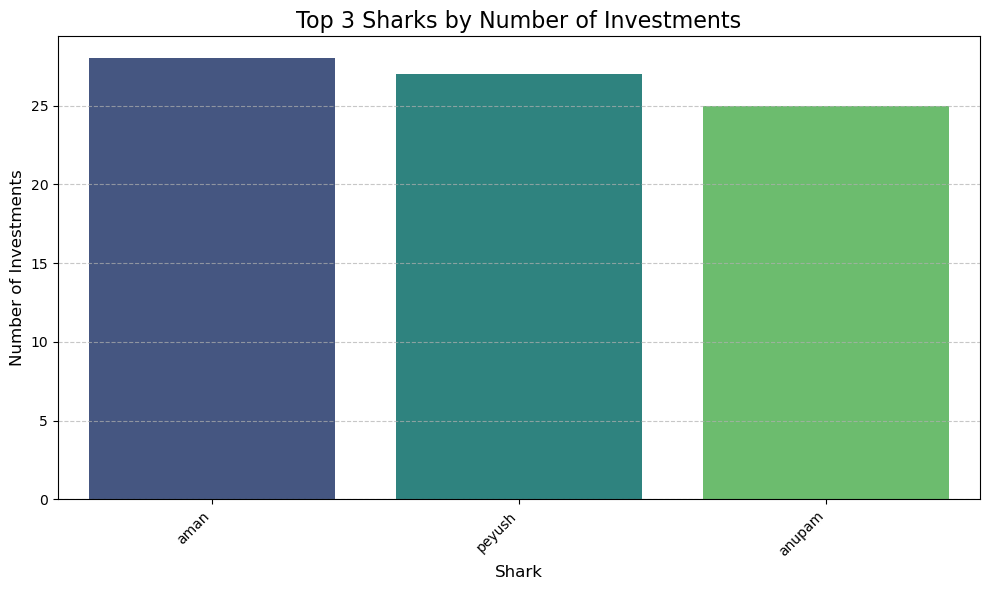

In [22]:
# Answer 3.	Which shark has made the highest number of investments? Provide a visualization of top 3 sharks.

# List of all shark deal columns
shark_deal_columns = [
    'ashneer_deal',
    'anupam_deal',
    'aman_deal',
    'namita_deal',
    'vineeta_deal',
    'peyush_deal',
    'ghazal_deal'
]

#calculate the total investments for each shark.
shark_investments = {}
for col in shark_deal_columns:
    shark_name = col.replace('_deal', '')
    shark_investments[shark_name] = sharktank_df[col].sum()

print(shark_investments)

## converting the shark_investments dictionary to a pandas Series, sorting it in descending order, and selecting the top 3 Investor
shark_investments_series = pd.Series(shark_investments)
top_3_sharks = shark_investments_series.sort_values(ascending=False).head(3)

print("Top 3 Sharks by Number of Investments:")
print(top_3_sharks)


Highest_Invested_shark= shark_investments_series.sort_values(ascending=False).head(1)
print("Highest Shark by Number of Investments:")
print(Highest_Invested_shark)

# Create the bar chart
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x=top_3_sharks.index, y=top_3_sharks.values, palette='viridis')
plt.title('Top 3 Sharks by Number of Investments', fontsize=16)
plt.xlabel('Shark', fontsize=12)
plt.ylabel('Number of Investments', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [23]:
shark_investments = sharktank_df[shark_deal_columns].sum().to_dict()
print(shark_investments)

{'ashneer_deal': 21, 'anupam_deal': 25, 'aman_deal': 28, 'namita_deal': 22, 'vineeta_deal': 16, 'peyush_deal': 27, 'ghazal_deal': 7}


## Question 4.	What is the total amount invested by all sharks combined in entire season

In [24]:
# Answer 4.	What is the total amount invested by all sharks combined in entire season

total_investment = sharktank_df['deal_amount'].sum()

print(f"The total amount invested by all sharks combined in the entire season is: {total_investment} lakhs.")

The total amount invested by all sharks combined in the entire season is: 3767.00106 lakhs.


## Question 5. 	How does the deal_equity distribution look? Are there any outliers?

C:\Users\richa\AppData\Local\Temp\ipykernel_35372\1229109130.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=sharktank_df['deal_equity'], palette='viridis')


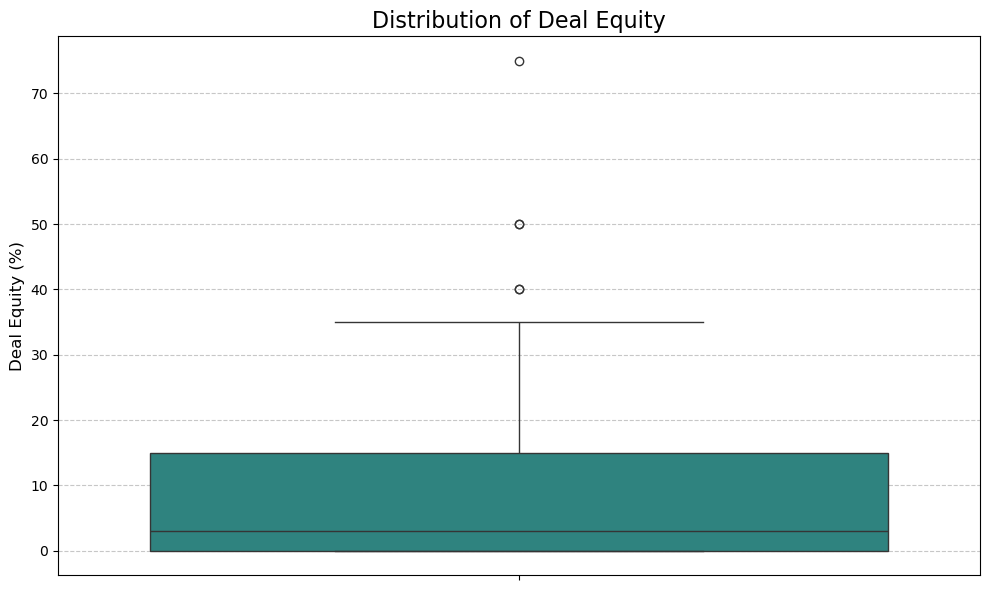


Interquartile Range (IQR) for Deal Equity: 15.00
Upper outlier limit: 37.50
Lower outlier limit: -22.50

Number of outliers in 'deal_equity': 5
Outliers (rows with deal equity outside 1.5*IQR range):


,brand_name,deal_equity
1,Booz scooters,50.0
43,Hammer Lifestyle,40.0
66,Sid07 Designs,75.0
77,KG Agrotech,40.0
82,Isak Fragrances,50.0


In [25]:
# Answer 5. How does the deal_equity distribution look? Are there any outliers?

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(y=sharktank_df['deal_equity'], palette='viridis')
plt.title('Distribution of Deal Equity', fontsize=16)
plt.ylabel('Deal Equity (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Calculate quartiles and IQR to programmatically identify outliers
Q1 = sharktank_df['deal_equity'].quantile(0.25)
Q3 = sharktank_df['deal_equity'].quantile(0.75)
IQR = Q3 - Q1

outlier_upper = Q3 + 1.5 * IQR
outlier_lower = Q1 - 1.5 * IQR

outliers = sharktank_df[(sharktank_df['deal_equity'] < outlier_lower) | (sharktank_df['deal_equity'] > outlier_upper)]

print(f"\nInterquartile Range (IQR) for Deal Equity: {IQR:.2f}")
print(f"Upper outlier limit: {outlier_upper:.2f}")
print(f"Lower outlier limit: {outlier_lower:.2f}")
print(f"\nNumber of outliers in 'deal_equity': {len(outliers)}")
print("Outliers (rows with deal equity outside 1.5*IQR range):")
display(outliers[['brand_name', 'deal_equity']])


## Question 6.	Find the correlation between deal_valuation and ask_valuation. What insight can be drawn from this?

Correlation between Deal Valuation and Ask Valuation: 0.02
Correlation Matrix:


,deal_valuation,ask_valuation
deal_valuation,1.000000,0.018925
ask_valuation,0.018925,1.000000


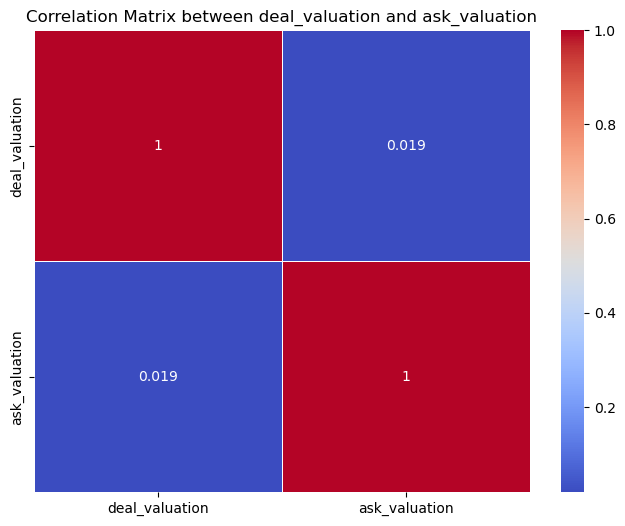

In [26]:
# Answer 6.	Find the correlation between deal_valuation and ask_valuation. What insight can be drawn from this?

# Calculate the correlation between 'deal_valuation' and 'ask_valuation'
correlation = sharktank_df['deal_valuation'].corr(sharktank_df['ask_valuation'])

print(f"Correlation between Deal Valuation and Ask Valuation: {correlation:.2f}")

# Calculate the correlation matrix
correlation_data = sharktank_df[['deal_valuation', 'ask_valuation']]
correlation_matrix = correlation_data.corr()
print("Correlation Matrix:")
display(correlation_matrix)

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix between deal_valuation and ask_valuation')
plt.show()

## A high positive correlation (close to 1) between deal_valuation and ask_valuation suggests that with higher initial valuations requested by the entrepreneurs (ask_valuation) tend to result in higher final valuations agreed upon in the deals (deal_valuation). Conversely, a low or negative correlation would indicate that the initial ask does not strongly influence the final deal valuation.

## This insight can be useful for understanding the negotiation trends on Shark Tank. If the correlation is high, it means that sharks are often agreeing to valuations that are in line with the entrepreneurs' initial asks, or at least they are alignining. If the correlation is low, it  mean that sharks are significantly adjusting the valuations regardless of the initial ask, perhaps due to strong negotiation.

## Question 7.	What is the average equity percentage given to the sharks per deal?

In [ ]:
# Answer 7.	What is the average equity percentage given to the sharks per deal?

# Calculate the average deal equity percentage
average_deal_equity = sharktank_df['deal_equity'].mean()

print(f"The average equity percentage given to the sharks per deal is: {average_deal_equity:.2f}%")

## Question 8.	Identify which episode had the highest number of deals and visualize it

Number of successful deals per episode:
episode_number
1     3
2     1
3     2
4     2
5     1
6     1
7     1
8     3
9     2
10    3
11    2
12    2
13    3
14    1
15    3
16    3
17    3
18    1
19    1
20    2
21    3
22    1
23    1
24    2
25    2
26    2
27    2
28    2
29    1
30    1
31    1
32    1
33    3
34    1
35    1
dtype: int64
Episodes 1, 8, 10, 13, 15, 16, 17, 21, 33 highlighted in green had the most successful deals, each with a total of 3 deals.


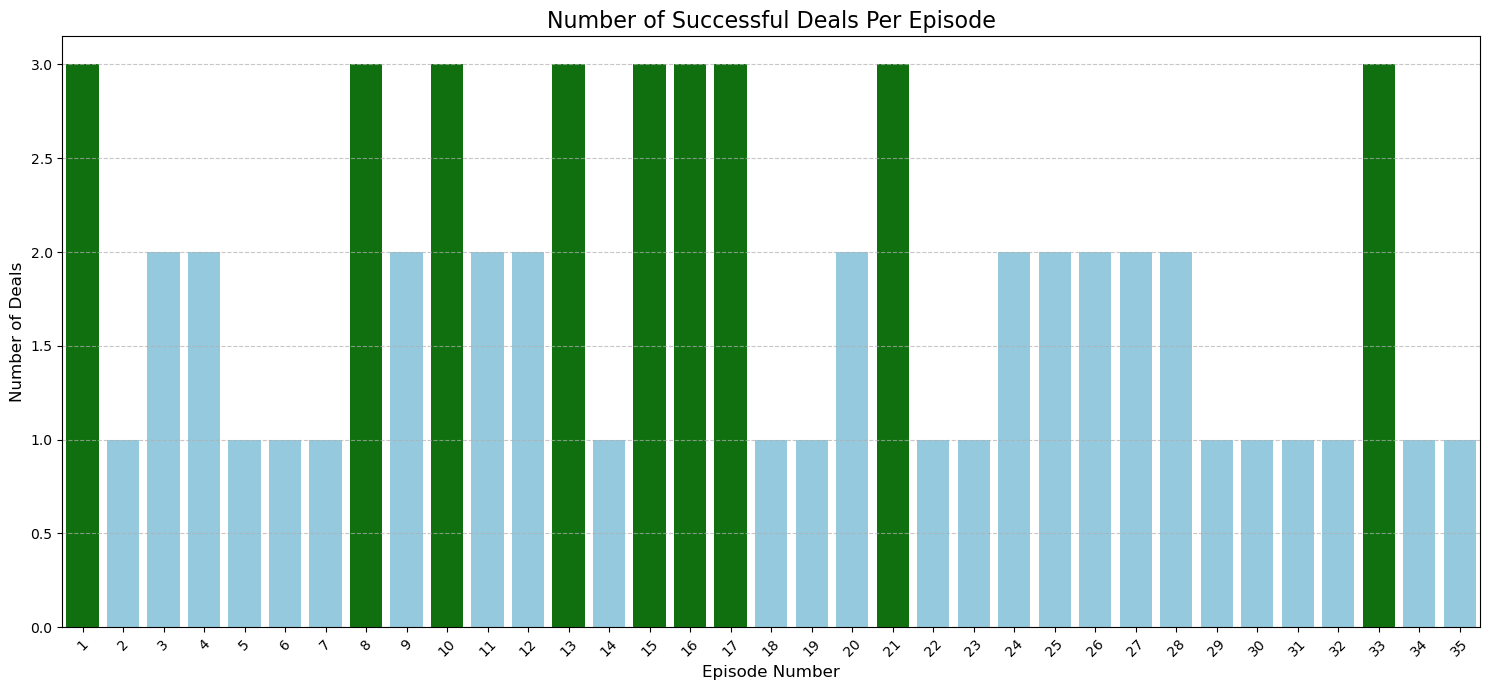

In [27]:
# Answer 8.	Identify which episode had the highest number of deals and visualize it

# filter out successful deals, where the value in the 'deal' column is equal to 1.

successful_deals_df = sharktank_df[sharktank_df['deal'] == '1']

#Group the `successful_deals_df` by the 'episode_number' column.

deals_per_episode = successful_deals_df.groupby('episode_number').size()

# 4. Display the `deals_per_episode` to see the count of successful deals for each episode.
print("Number of successful deals per episode:")
print(deals_per_episode)

# Find the episode_number with the maximum number of successful deals
episode_with_most_deals = deals_per_episode.idxmax()

# 2. Get the maximum number of successful deals
max_deals_count = deals_per_episode.max()

# Find all episode_numbers with the maximum number of successful deals
episodes_with_most_deals = deals_per_episode[deals_per_episode == max_deals_count].index.tolist()


# Print the identified episode numbers and the corresponding maximum deal count
if len(episodes_with_most_deals) > 1:
    print(f"Episodes {', '.join(map(str, episodes_with_most_deals))} highlighted in green had the most successful deals, each with a total of {max_deals_count} deals.")
else:
    print(f"Episode {episodes_with_most_deals[0]} highlighted in green had the most successful deals with a total of {max_deals_count} deals.")

# Plot Bar chart
plt.figure(figsize=(15, 7))

colors = ['green' if episode in episodes_with_most_deals else 'skyblue' for episode in deals_per_episode.index]

sns.barplot(x=deals_per_episode.index, y=deals_per_episode.values, hue=deals_per_episode.index, palette=colors, legend=False)

plt.title('Number of Successful Deals Per Episode', fontsize=16)
plt.xlabel('Episode Number', fontsize=12)
plt.ylabel('Number of Deals', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Question 9.	How many pitches asked for more than ₹1 crore and how many of those received investments?

In [41]:
# Answer 9.	How many pitches asked for more than ₹1 crore and how many of those received investments?

# Filter for pitches that asked for more than ₹1 crore
pitches_above_1cr = sharktank_df[sharktank_df['pitcher_ask_amount'] > 100]

# Count the total number of such pitches
num_pitches_above_1cr = len(pitches_above_1cr)

# From these pitches, count how many received an investment
pitches_above_1cr_with_deal = (pitches_above_1cr['deal'] == '1').count()


print(f"Number of pitches that asked for more than ₹1 crore: {num_pitches_above_1cr}")
print(f"Number of those pitches that received investments: {pitches_above_1cr_with_deal}")

Number of pitches that asked for more than ₹1 crore: 7
Number of those pitches that received investments: 7


## Question 10.	What percentage of pitches involved more than one shark investing together?

In [42]:
# Answer 10.  What percentage of pitches involved more than one shark investing together?
# Filter for pitches where a deal was made (deal == 1)
deals_made_df = sharktank_df[sharktank_df['deal'] == '1']

# Count the total number of deals
total_num_deals = len(deals_made_df)
print(f"Total No of Deals: {total_num_deals}")

# Filter for deals where more than one shark invested
multiple_sharks_deals = deals_made_df[deals_made_df['total_sharks_invested'] > 1]
multiple_sharks_deals=multiple_sharks_deals.shape[0]
print(f"Total No of Deals where more than one shark invested: {multiple_sharks_deals}")

# Calculate the percentage
if total_num_deals > 0:
    percentage_multiple_sharks = (multiple_sharks_deals / total_num_deals) * 100
    print(f"Percentage of pitches involving more than one shark investing together: {percentage_multiple_sharks:.2f}%")
else:
    print("No deals were made, so percentage cannot be calculated.")

Total No of Deals: 64
Total No of Deals where more than one shark invested: 41
Percentage of pitches involving more than one shark investing together: 64.06%


## Question 11.	How does the investment behavior of Ashneer Grover compare with Peyush Bansal in terms of total amount invested?

Peyush Bansal's total investment: 1556.00 lakhs.
Ashneer Grover's total investment: 1316.00 lakhs.


C:\Users\richa\AppData\Local\Temp\ipykernel_35372\3616435738.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=investment_series.index, y=investment_series.values, palette='viridis')


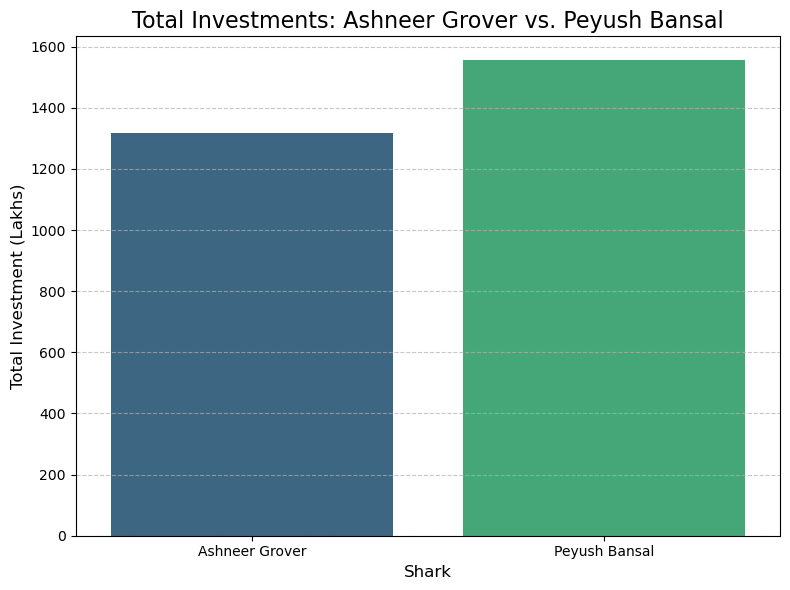

In [43]:
# Answer 11. How does the investment behavior of Ashneer Grover compare with Peyush Bansal in terms of total amount invested?

#Peyush Bansal's total investment
peyush_deals_df = sharktank_df[sharktank_df['peyush_deal'] == 1.0]
peyush_total_investment = peyush_deals_df['deal_amount'].sum()

#Ashneer Grover's total investment
ashneer_deals_df = sharktank_df[sharktank_df['ashneer_deal'] == 1.0]
ashneer_total_investment = ashneer_deals_df['deal_amount'].sum()

print(f"Peyush Bansal's total investment: {peyush_total_investment:.2f} lakhs.")
print(f"Ashneer Grover's total investment: {ashneer_total_investment:.2f} lakhs.")

# Create Bar chart for Investment
investment_data = {
    'Ashneer Grover': ashneer_total_investment,
    'Peyush Bansal': peyush_total_investment
}
investment_series = pd.Series(investment_data)

# 2. Create a bar chart to visualize total investments for Peyush Bansal vs Ashneer Grover
plt.figure(figsize=(8, 6))
sns.barplot(x=investment_series.index, y=investment_series.values, palette='viridis')
plt.title('Total Investments: Ashneer Grover vs. Peyush Bansal', fontsize=16)
plt.xlabel('Shark', fontsize=12)
plt.ylabel('Total Investment (Lakhs)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Question 12.	Create a box plot to analyze amount_per_shark. What insights can be gathered?

C:\Users\richa\AppData\Local\Temp\ipykernel_35372\684091555.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=sharktank_df['amount_per_shark'], palette='viridis')


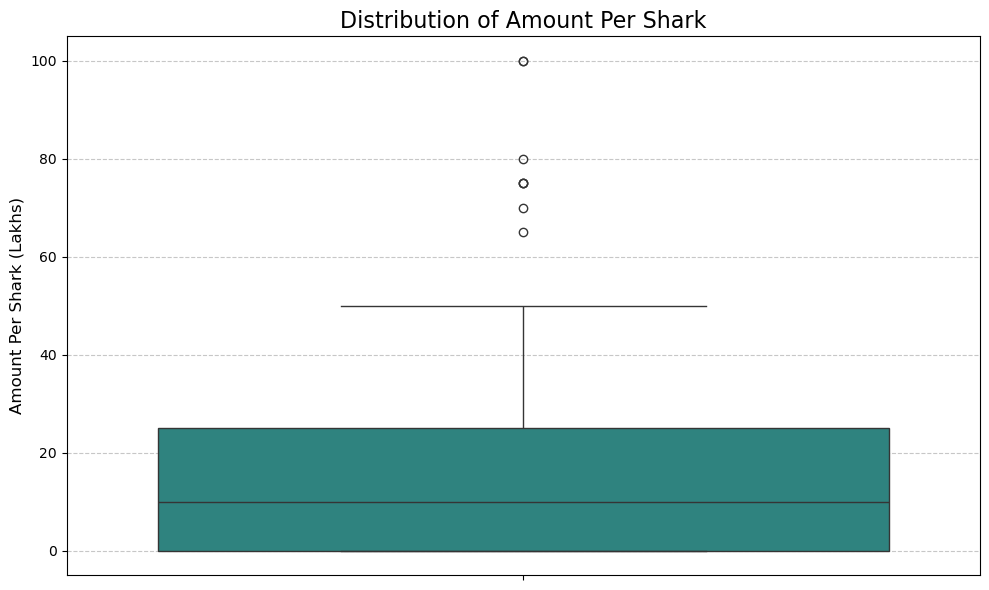

Median of Amount Per Shark: 10.00 lakhs
First Quartile (Q1): 0.00 lakhs
Third Quartile (Q3): 25.00 lakhs
Interquartile Range (IQR): 25.00 lakhs
Upper Outlier Fence: 62.50 lakhs
Lower Outlier Fence: -37.50 lakhs

Number of potential outliers in 'amount_per_shark': 8
Potential outliers (brand names and amount per shark):


,brand_name,amount_per_shark
3,Tagz Foods,70.0
7,Peeschute,75.0
34,Auli Lifestyle,75.0
43,Hammer Lifestyle,100.0
53,RoadBounce,80.0
84,Rare Planet,65.0
88,Insurance Samadhan,100.0
102,AyuRythm,75.0


In [44]:
# Answer 12. Create a box plot to analyze amount_per_shark. What insights can be gathered?

plt.figure(figsize=(10, 6))

# Generate a box plot for 'amount_per_shark'
sns.boxplot(y=sharktank_df['amount_per_shark'], palette='viridis')

plt.title('Distribution of Amount Per Shark', fontsize=16)
plt.ylabel('Amount Per Shark (Lakhs)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Calculate the median, Q1, and Q3 for 'amount_per_shark'
median_amount_per_shark = sharktank_df['amount_per_shark'].median()
Q1_amount_per_shark = sharktank_df['amount_per_shark'].quantile(0.25)
Q3_amount_per_shark = sharktank_df['amount_per_shark'].quantile(0.75)
# Calculate the Interquartile Range (IQR)
IQR_amount_per_shark = Q3_amount_per_shark - Q1_amount_per_shark

# Calculate the outlier fences
upper_fence_amount_per_shark = Q3_amount_per_shark + 1.5 * IQR_amount_per_shark
lower_fence_amount_per_shark = Q1_amount_per_shark - 1.5 * IQR_amount_per_shark

# Identify potential outliers
outliers_amount_per_shark = sharktank_df[
    (sharktank_df['amount_per_shark'] < lower_fence_amount_per_shark) | 
    (sharktank_df['amount_per_shark'] > upper_fence_amount_per_shark)
]

print(f"Median of Amount Per Shark: {median_amount_per_shark:.2f} lakhs")
print(f"First Quartile (Q1): {Q1_amount_per_shark:.2f} lakhs")
print(f"Third Quartile (Q3): {Q3_amount_per_shark:.2f} lakhs")
print(f"Interquartile Range (IQR): {IQR_amount_per_shark:.2f} lakhs")
print(f"Upper Outlier Fence: {upper_fence_amount_per_shark:.2f} lakhs")
print(f"Lower Outlier Fence: {lower_fence_amount_per_shark:.2f} lakhs")

print(f"\nNumber of potential outliers in 'amount_per_shark': {len(outliers_amount_per_shark)}")
print("Potential outliers (brand names and amount per shark):")
display(outliers_amount_per_shark[['brand_name', 'amount_per_shark']])

## Conclusion :  The distribution of amount_per_shark is right-skewed. This is evident because the median (10 lakhs) is much closer to Q1 (0 lakhs) than to Q3 (25 lakhs), and there are several significant outliers on the higher end.
## While most individual investments are in the lower range, there are specific instances where sharks invest substantially larger amounts. These outliers represent high-value deals or significant individual contributions to a larger deal.

## Question 13.	Are there any cases where the deal_amount exceeded the pitcher_ask_amount? If yes, list those cases.

In [45]:
# Answer 13. Are there any cases where the deal_amount exceeded the pitcher_ask_amount? If yes, list those cases.

#find out scenario where 'deal_amount' exceeded 'pitcher_ask_amount'
exceeding_deals = sharktank_df[sharktank_df['deal_amount'] > sharktank_df['pitcher_ask_amount']]

# Display the relevant columns for these cases

print(f"Number of deals where deal_amount exceeded pitcher_ask_amount: {len(exceeding_deals)}")
print("Details of these deals:")
display(exceeding_deals[['brand_name', 'pitcher_ask_amount', 'deal_amount']])


Number of deals where deal_amount exceeded pitcher_ask_amount: 10
Details of these deals:


,brand_name,pitcher_ask_amount,deal_amount
0,BluePine Industries,50.0,75.0
16,Skippi Pops,45.0,100.0
37,Annie,30.0,105.0
39,The Yarn Bazaar,50.0,100.0
43,Hammer Lifestyle,30.0,100.0
59,WeSTOCK,50.0,60.0
64,IN A CAN,50.0,100.0
76,The Sass Bar,40.0,50.0
90,Humpy A2,75.0,100.0
110,Tweek Labs,40.0,60.0


## Question 14.	Which shark has the highest return on investment (ROI) based on deal_amount vs. deal_equity?

C:\Users\richa\AppData\Local\Temp\ipykernel_35372\1071907472.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  successful_deals_df['equity_per_shark'] = pd.to_numeric(successful_deals_df['equity_per_shark'], errors='coerce').fillna(0.0)
C:\Users\richa\AppData\Local\Temp\ipykernel_35372\1071907472.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  successful_deals_df['amount_per_shark'] = pd.to_numeric(successful_deals_df['amount_per_shark'], errors='coerce').fillna(0.0)
C:\Users\richa\AppData\Local\Tem

Average 'Equity per Amount Invested' (ROI Ratio) per individual Shark:
namita     4941.230634
anupam     4323.702744
aman       3838.730767
ghazal      566.098006
peyush      147.265219
vineeta       0.422432
ashneer       0.292923
dtype: float64
The shark with the highest average 'Equity per Amount Invested' (ROI Ratio) is namita with an average ratio of 4941.23.


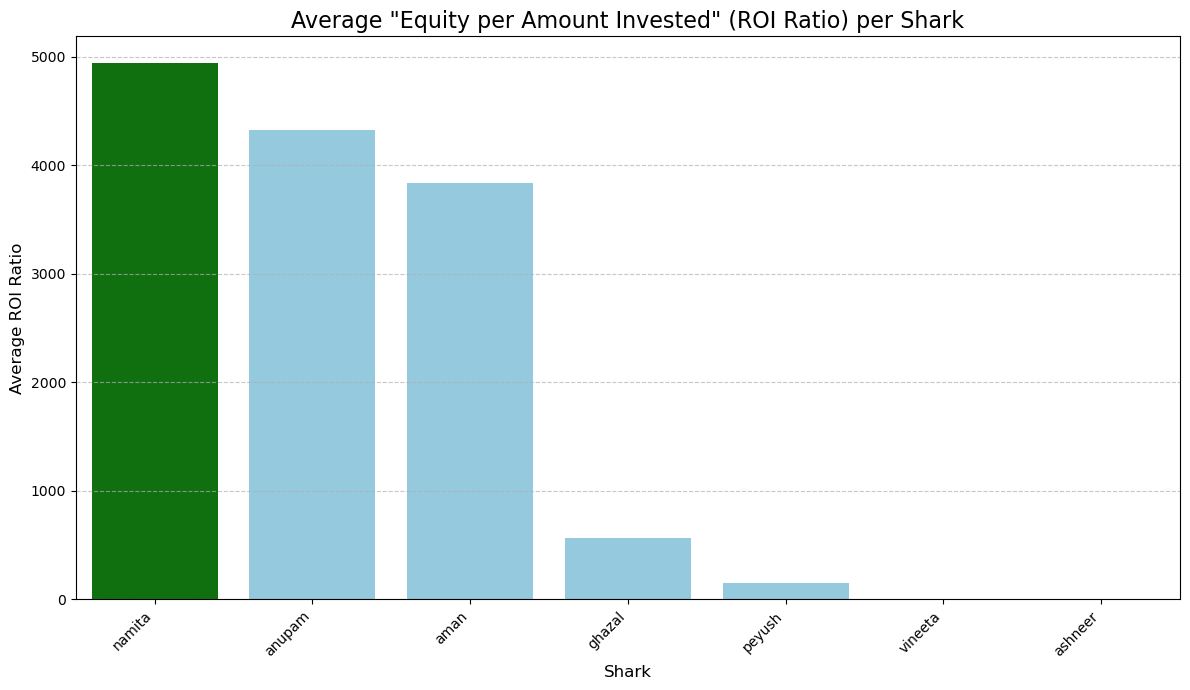

In [46]:
# Answer 14. Which shark has the highest return on investment (ROI) based on deal_amount vs. deal_equity?

#  Create a list of shark deal columns
shark_deal_columns = [
    'ashneer_deal', 'anupam_deal', 'aman_deal', 'namita_deal',
    'vineeta_deal', 'peyush_deal', 'ghazal_deal'
]

# filter out successful deals, where the value in the 'deal' column is equal to 1.
successful_deals_df = sharktank_df[sharktank_df['deal'] == '1']

# convert 'equity_per_shark' and 'amount_per_shark' as numeric,handle non-numeric values by coercing them to NaN and then filling with 0

successful_deals_df['equity_per_shark'] = pd.to_numeric(successful_deals_df['equity_per_shark'], errors='coerce').fillna(0.0)
successful_deals_df['amount_per_shark'] = pd.to_numeric(successful_deals_df['amount_per_shark'], errors='coerce').fillna(0.0)

# 3. Initialize an empty dictionary, shark_roi_data, to store the average ROI for each shark.
shark_roi_data = {}

#Iterate each shark's deal column and Extract shark name:
for col_name in shark_deal_columns:
    shark_name = col_name.replace('_deal', '')


# filter the successful deals for individual shark, and include only deals where that shark invested (their deal column is 1.0).
    shark_invested_deals = successful_deals_df[successful_deals_df[col_name] == 1.0]

# Skip if the shark didn't invest in any successful deals or if all investments were 0 amount
    if shark_invested_deals.empty or shark_invested_deals['amount_per_shark'].sum() == 0:
       shark_roi_data[shark_name] = 0.0
       continue 
    

# Create a newcolumn, `roi_ratio`, by dividing `equity_per_shark` by `amount_per_shark`.
# c. Handle division by zero: If `amount_per_shark` is 0, set the `roi_ratio` for that deal to 0.
    shark_invested_deals['roi_ratio'] = shark_invested_deals.apply(
        lambda row: row['equity_per_shark'] / row['amount_per_shark'] if row['amount_per_shark'] != 0 else 0.0,
        axis=1
    )

# Calculate the average of  `roi_ratio` for the individual shark.
    average_roi = shark_invested_deals['roi_ratio'].mean()

# keep the shark's individual name and their calculated average ROI in the `shark_roi_data` dictionary.
    shark_roi_data[shark_name] = average_roi

#Convert the `shark_roi_data` dictionary into a pandas Series and print it.
    shark_average_roi_series = pd.Series(shark_roi_data).sort_values(ascending=False)

print("Average 'Equity per Amount Invested' (ROI Ratio) per individual Shark:")
print(shark_average_roi_series)

highest_roi_shark = shark_average_roi_series.index[0]
highest_roi_value = shark_average_roi_series.iloc[0]

print(f"The shark with the highest average 'Equity per Amount Invested' (ROI Ratio) is {highest_roi_shark} with an average ratio of {highest_roi_value:.2f}.")

# Create a bar plot for the ROI
plt.figure(figsize=(12, 7))

colors = ['green' if shark == highest_roi_shark else 'skyblue' for shark in shark_average_roi_series.index]

sns.barplot(x=shark_average_roi_series.index, y=shark_average_roi_series.values, hue=shark_average_roi_series.index, palette=colors, legend=False)

plt.title('Average "Equity per Amount Invested" (ROI Ratio) per Shark', fontsize=16)
plt.xlabel('Shark', fontsize=12)
plt.ylabel('Average ROI Ratio', fontsize=12)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add a grid to the y-axis
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Ensure tight layout
plt.tight_layout()

# Display the plot
plt.show()


## Question 15.	Identify trends in equity distribution—are sharks investing in lower or higher equity stakes over time?

In [ ]:
# Answer 15. Identify trends in equity distribution—are sharks investing in lower or higher equity stakes over time?

# Convert 'deal_equity' column to numeric, coercing errors to NaN and fill NaN with 0
sharktank_df['deal_equity'] = pd.to_numeric(sharktank_df['deal_equity'], errors='coerce').fillna(0)

print("Value counts of 'deal_equity' column after numeric conversion and fillna:")
print(sharktank_df['deal_equity'].value_counts())

#Calculate the mean of the 'deal_equity' column for each episode
average_equity_per_episode = sharktank_df.groupby('episode_number')['deal_equity'].mean()
print("Average Deal Equity per Episode:")
print(average_equity_per_episode)

# Create a line plot
plt.figure(figsize=(12, 7))
sns.lineplot(x=average_equity_per_episode.index, y=average_equity_per_episode.values, marker='o')
plt.title('Trend of Average Deal Equity Over Episodes', fontsize=16)
plt.xlabel('Episode Number', fontsize=12)
plt.ylabel('Average Deal Equity (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Question 16.	What is the relationship between pitcher_ask_amount and deal_amount? Do pitchers who ask for less tend to secure more deals?

'pitcher_ask_amount' and 'deal_amount' columns are ready.

Data type of 'pitcher_ask_amount': float64
Data type of 'deal_amount': float64

Value counts for 'pitcher_ask_amount' after preparation:
pitcher_ask_amount
50.00000       32
100.00000      16
75.00000       14
40.00000        9
30.00000        9
80.00000        5
35.00000        4
60.00000        4
45.00000        3
25.00000        3
90.00000        2
65.00000        2
150.00000       2
70.00000        1
56.00000        1
10.00000        1
30000.00000     1
5.00000         1
120.00000       1
125.00000       1
15.00000        1
47.00000        1
20.00000        1
0.00101         1
300.00000       1
200.00000       1
Name: count, dtype: int64

Value counts for 'deal_amount' after preparation:
deal_amount
0.00000      52
50.00000     15
100.00000    11
75.00000      7
40.00000      6
25.00000      5
30.00000      4
60.00000      3
80.00000      2
10.00000      2
70.00000      1
56.00000      1
20.00000      1
45.00000      1
0.00

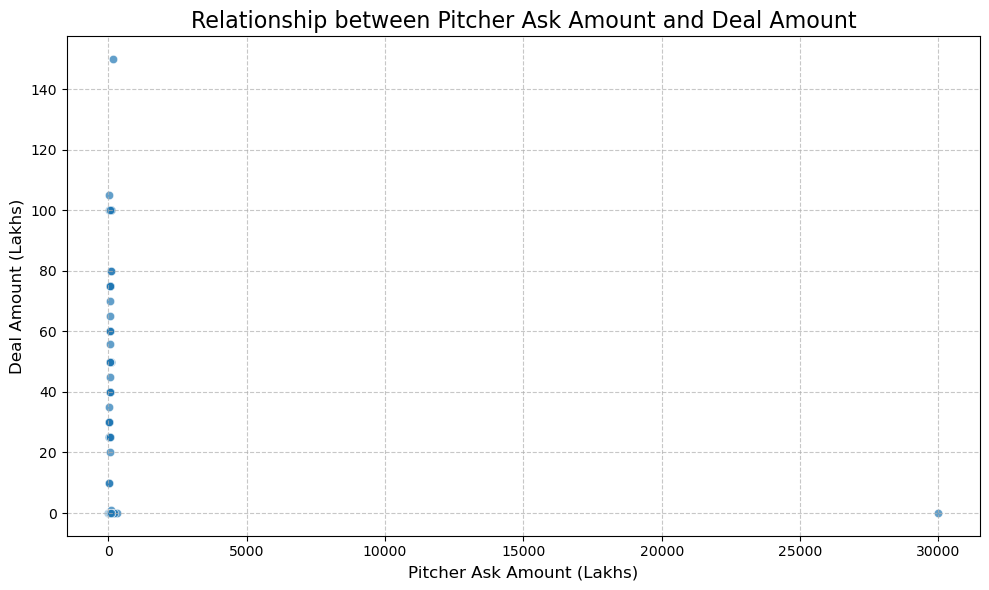

Correlation coefficient between Pitcher Ask Amount and Deal Amount: -0.08
Deal Success Rate by Pitcher Ask Amount Category:
ask_amount_category
Low       0.647059
Medium    0.518987
High      0.200000
Name: deal, dtype: float64


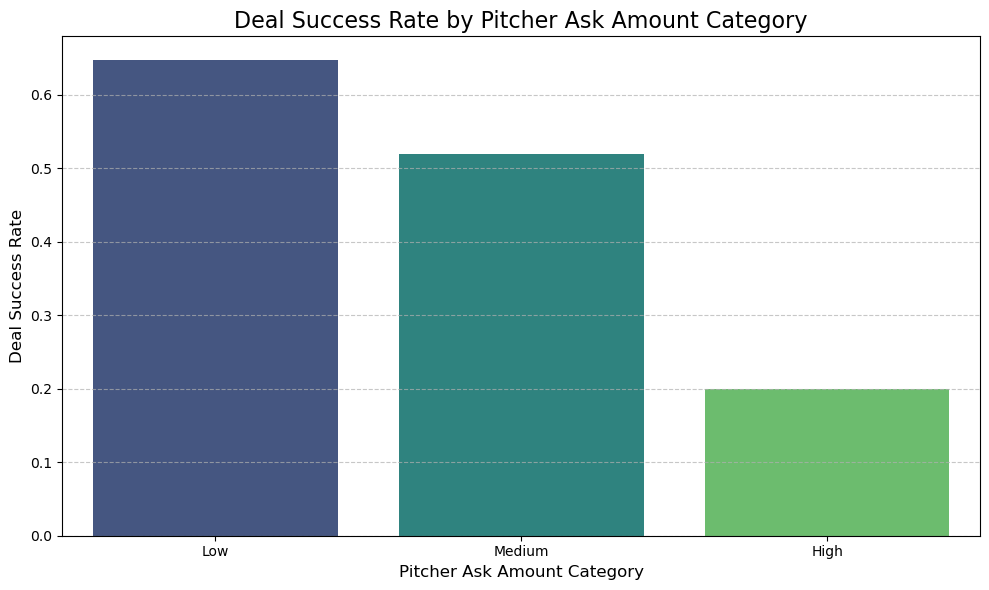

In [47]:
#  Answer 16.	What is the relationship between pitcher_ask_amount and deal_amount? Do pitchers who ask for less tend to secure more deals?

# Convert 'pitcher_ask_amount' column to numeric, and coercing errors to NaN and fill NaN with 0
sharktank_df['pitcher_ask_amount'] = pd.to_numeric(sharktank_df['pitcher_ask_amount'], errors='coerce').fillna(0)

# Convert 'deal_amount' column to numeric,  and coercing errors to NaN and fill NaN with 0
sharktank_df['deal_amount'] = pd.to_numeric(sharktank_df['deal_amount'], errors='coerce').fillna(0)

print("'pitcher_ask_amount' and 'deal_amount' columns are ready.")

print(f"\nData type of 'pitcher_ask_amount': {sharktank_df['pitcher_ask_amount'].dtype}")
print(f"Data type of 'deal_amount': {sharktank_df['deal_amount'].dtype}")

print("\nValue counts for 'pitcher_ask_amount' after preparation:")
print(sharktank_df['pitcher_ask_amount'].value_counts())
print("\nValue counts for 'deal_amount' after preparation:")
print(sharktank_df['deal_amount'].value_counts())


# Create a scatter Plot
plt.figure(figsize=(10, 6))

sns.scatterplot(x=sharktank_df['pitcher_ask_amount'], y=sharktank_df['deal_amount'], alpha=0.7)
plt.title('Relationship between Pitcher Ask Amount and Deal Amount', fontsize=16)
plt.xlabel('Pitcher Ask Amount (Lakhs)', fontsize=12)
plt.ylabel('Deal Amount (Lakhs)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Calculate the correlation coefficient between 'pitcher_ask_amount' and 'deal_amount'
correlation = sharktank_df['pitcher_ask_amount'].corr(sharktank_df['deal_amount'])

print(f"Correlation coefficient between Pitcher Ask Amount and Deal Amount: {correlation:.2f}")


# Next step:  'deal' column is numeric, coercing errors to NaN and filling with 0
sharktank_df['deal'] = pd.to_numeric(sharktank_df['deal'], errors='coerce').fillna(0.0)

# Define bins and labels for 'pitcher_ask_amount'
bins = [0, 50, 150, sharktank_df['pitcher_ask_amount'].max() + 1] # +1 to ensure max value is included
labels = ['Low', 'Medium', 'High']

# Create a new column for ask amount categories
sharktank_df['ask_amount_category'] = pd.cut(sharktank_df['pitcher_ask_amount'], bins=bins, labels=labels, right=False, include_lowest=True)

# Calculate average deal success rate by ask amount category
deal_success_rate_by_category = sharktank_df.groupby('ask_amount_category', observed=True)['deal'].mean()

print("Deal Success Rate by Pitcher Ask Amount Category:")
print(deal_success_rate_by_category)

# Create a figure and axes for the plot
plt.figure(figsize=(10, 6))
sns.barplot(x=deal_success_rate_by_category.index, y=deal_success_rate_by_category.values, hue=deal_success_rate_by_category.index, palette='viridis', legend=False)
plt.title('Deal Success Rate by Pitcher Ask Amount Category', fontsize=16)
plt.xlabel('Pitcher Ask Amount Category', fontsize=12)
plt.ylabel('Deal Success Rate', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Conclusion : Pitchers are significantly more likely to secure a deal when their ask amount is lower. This suggests a strategy in asking for a more conservative amount to increase the probability of investment.
## 'Low' ask amounts (0-50 lakhs): 64.71% deal success rate.
## 'Medium' ask amounts (50-150 lakhs): 51.90% deal success rate.
## 'High' ask amounts (above 150 lakhs): 20.00% deal success rate.

## Question 17.	Identify if there is a pattern in episode-wise deal closures—do certain episodes see more investments?

Number of successful deals per episode:
episode_number
1     3
2     1
3     2
4     2
5     1
6     1
7     1
8     3
9     2
10    3
11    2
12    2
13    3
14    1
15    3
16    3
17    3
18    1
19    1
20    2
21    3
22    1
23    1
24    2
25    2
26    2
27    2
28    2
29    1
30    1
31    1
32    1
33    3
34    1
35    1
dtype: int64
Episodes 1, 8, 10, 13, 15, 16, 17, 21, 33 highlighted in green had the most successful deals, each with a total of 3 deals.


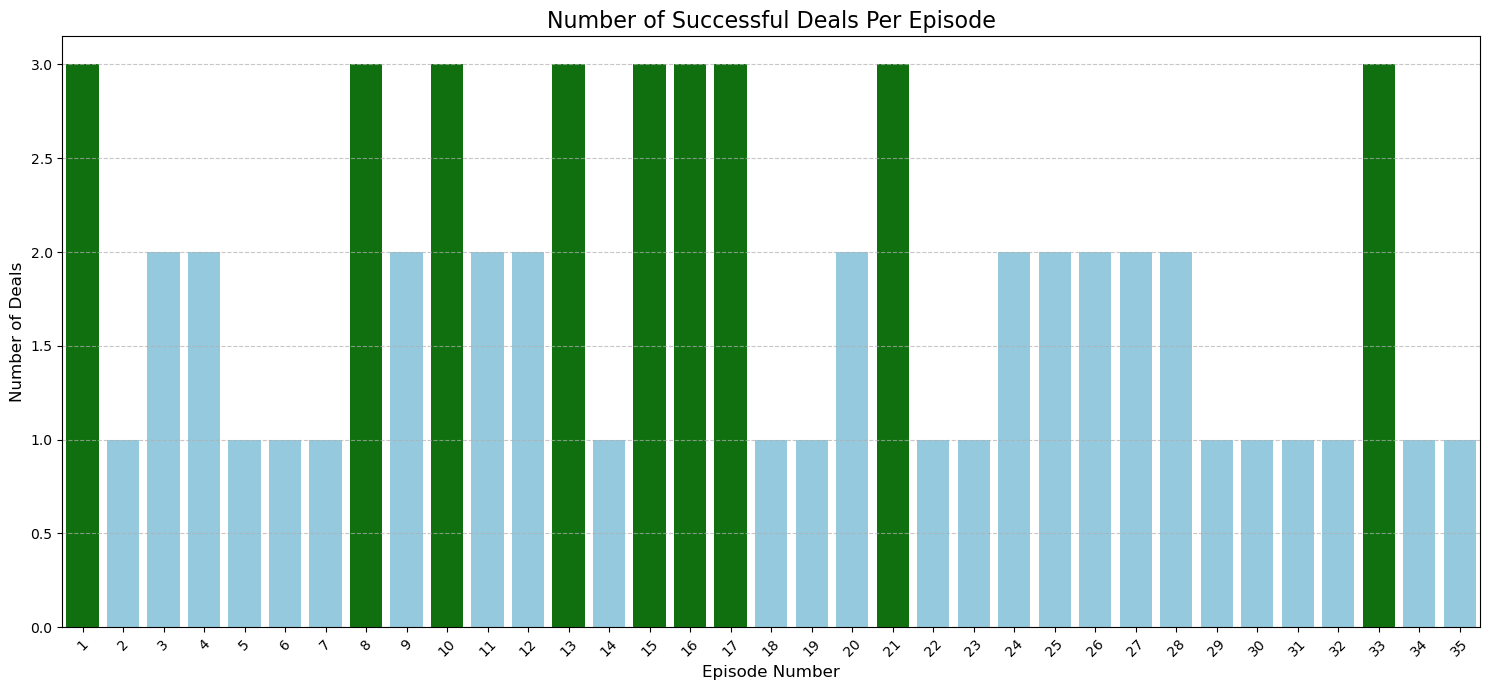

In [48]:
# Answer 17. Identify if there is a pattern in episode-wise deal closures—do certain episodes see more investments?

# filter out successful deals, where the value in the 'deal' column is equal to 1.

successful_deals_df = sharktank_df[sharktank_df['deal'] == 1]

#Group the `successful_deals_df` by the 'episode_number' column.

deals_per_episode = successful_deals_df.groupby('episode_number').size()

# 4. Display the `deals_per_episode` to see the count of successful deals for each episode.
print("Number of successful deals per episode:")
print(deals_per_episode)

# Find the episode_number with the maximum number of successful deals
episode_with_most_deals = deals_per_episode.idxmax()

# 2. Get the maximum number of successful deals
max_deals_count = deals_per_episode.max()

# Find all episode_numbers with the maximum number of successful deals
episodes_with_most_deals = deals_per_episode[deals_per_episode == max_deals_count].index.tolist()


# Print the identified episode numbers and the corresponding maximum deal count
if len(episodes_with_most_deals) > 1:
    print(f"Episodes {', '.join(map(str, episodes_with_most_deals))} highlighted in green had the most successful deals, each with a total of {max_deals_count} deals.")
else:
    print(f"Episode {episodes_with_most_deals[0]} highlighted in green had the most successful deals with a total of {max_deals_count} deals.")

# Plot Bar chart
plt.figure(figsize=(15, 7))

colors = ['green' if episode in episodes_with_most_deals else 'skyblue' for episode in deals_per_episode.index]

sns.barplot(x=deals_per_episode.index, y=deals_per_episode.values, hue=deals_per_episode.index, palette=colors, legend=False)

plt.title('Number of Successful Deals Per Episode', fontsize=16)
plt.xlabel('Episode Number', fontsize=12)
plt.ylabel('Number of Deals', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Conclusion : The number of successful deals varied significantly across episodes, ranging from 0 to 3.
## Nine episodes (1, 8, 10, 13, 15, 16, 17, 21, and 33) tied for the highest number of successful deals, each securing 3 deals.
## The visualization clearly depicted the distribution of deals per episode, highlighting the episodes that achieved the maximum deal count.

## Question 18.	Analyze the impact of equity dilution on deal_valuation. Are lower equity asks leading to higher deal valuations?

In [ ]:
# Answer  18.	Analyze the impact of equity dilution on deal_valuation. Are lower equity asks leading to higher deal valuations?

# Convert 'ask_equity' column to numeric, coercing errors to NaN and Fill any NaN values with 0
sharktank_df['ask_equity'] = pd.to_numeric(sharktank_df['ask_equity'], errors='coerce').fillna(0)


# Convert 'deal_valuation' column to numeric, coercing errors to NaN and Fill any NaN values with 0
sharktank_df['deal_valuation'] = pd.to_numeric(sharktank_df['deal_valuation'], errors='coerce').fillna(0)

print("'ask_equity' and 'deal_valuation' columns prepared.")

print(f"\nData type of 'ask_equity': {sharktank_df['ask_equity'].dtype}")
print(f"Data type of 'deal_valuation': {sharktank_df['deal_valuation'].dtype}")

print("\nValue counts for 'ask_equity' after preparation:")
print(sharktank_df['ask_equity'].value_counts())
print("\nValue counts for 'deal_valuation' after preparation:")
print(sharktank_df['deal_valuation'].value_counts())

import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: deal_equity vs. deal_valuation
sns.scatterplot(x=sharktank_df['deal_equity'], y=sharktank_df['deal_valuation'], ax=axes[0], alpha=0.7)
axes[0].set_title('Relationship between Deal Equity and Deal Valuation', fontsize=16)
axes[0].set_xlabel('Deal Equity (%)', fontsize=12)
axes[0].set_ylabel('Deal Valuation (Lakhs)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: ask_equity vs. deal_valuation
sns.scatterplot(x=sharktank_df['ask_equity'], y=sharktank_df['deal_valuation'], ax=axes[1], alpha=0.7)
axes[1].set_title('Relationship between Ask Equity and Deal Valuation', fontsize=16)
axes[1].set_xlabel('Ask Equity (%)', fontsize=12)
axes[1].set_ylabel('Deal Valuation (Lakhs)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.7)

# Ensure tight layout
plt.tight_layout()

# Display the plots
plt.show()


# Calculate the correlation coefficient between 'deal_equity' and 'deal_valuation'
correlation_deal_equity_valuation = sharktank_df['deal_equity'].corr(sharktank_df['deal_valuation'])

# Calculate the correlation coefficient between 'ask_equity' and 'deal_valuation'
correlation_ask_equity_valuation = sharktank_df['ask_equity'].corr(sharktank_df['deal_valuation'])

# Print the calculated correlation coefficients
print(f"Correlation coefficient between Deal Equity and Deal Valuation: {correlation_deal_equity_valuation:.2f}")
print(f"Correlation coefficient between Ask Equity and Deal Valuation: {correlation_ask_equity_valuation:.2f}")

## Conclusion : Correlation between Deal Equity and Deal Valuation: The correlation coefficient was calculated as -0.09, indicating a very weak negative relationship.
## Weak correlation between 'deal_equity' and 'deal_valuation' suggests that the percentage of equity given in a deal does not strongly dictate the overall valuation agreed upon
## Correlation between Ask Equity and Deal Valuation: The correlation coefficient was calculated as -0.31, indicating a weak to moderate negative relationship.
## The moderate negative correlation between 'ask_equity' and 'deal_valuation' aligns with negotiation expectations: a higher initial ask for equity often corresponds to a lower valuation being finalized
## Pitchers are more likely to achieve higher company valuations by asking for lower equity percentages. This suggests that a lower initial demand for equity may signal confidence and a stronger bargaining position, leading to better valuation outcomes.